In [64]:
import numpy as np
import matplotlib.pyplot as plt

In [65]:
def simpson_13(a, b, discrete_data):
  if len(discrete_data) < 3 or (len(discrete_data)-1)%2 != 0:
    raise ValueError("Simpson's 1/3 rule requires an even number of intervals (odd number of points).")
  x_points = np.linspace(a, b, len(discrete_data))
  dx = (b-a) / (len(discrete_data)-1)
  y_values = np.array(discrete_data)
  sum_value = (dx/3) * (y_values[0] + y_values[-1] + 4*np.sum(y_values[1:-1:2]) + 2*np.sum(y_values[2:-2:2]))
  return sum_value, x_points, dx, y_values

In [66]:
def simpson_38(a, b, discrete_data):
  if len(discrete_data) < 4 or (len(discrete_data)-1)%3 != 0:
    raise ValueError("Simpson's 3/83 rule requires the number of intervals to be a multiple of 3.")
  x_points = np.linspace(a, b, len(discrete_data))
  dx = (b-a) / (len(discrete_data)-1)
  y_values = np.array(discrete_data)
  sum_value = (3*dx/8) * (y_values[0] + y_values[-1] + 3*np.sum(y_values[1:-1:3]) + 3*np.sum(y_values[2:-2:3]))
  return sum_value, x_points, dx, y_values

In [67]:
def plot_simpson(a, b, method, discrete_data):
  if method == '1/3':
    sum_value, x_points, dx, y_values = simpson_13(a, b, discrete_data)
    method_name = "Simpson's 1/3 Rule"
  elif method == '3/8':
    sum_value, x_points, dx, y_values = simpson_38(a, b, discrete_data)
    method_name = "Simpson's 3/8 Rule"
  else:
    raise ValueError("Method must be '1/3' or '3/8'")
  plt.figure(figsize=(8, 5))
  plt.scatter(x_points, y_values, color='red', label='Discrete Data')
  plt.plot(x_points, y_values, 'b-', alpha=0.6)
  for i in range(len(x_points)-1):
    plt.fill_between([x_points[i], x_points[i+1]], [y_values[i], y_values[i+1]], alpha=0.4, color='blue', edgecolor='black')
  plt.title(f'{method_name}\nApproximate Integral: {sum_value:.5f}')
  plt.xlabel('x')
  plt.ylabel('f(x)')
  plt.legend()
  plt.show()

In [68]:
# Example with discrete data
a, b = 0, np.pi
n = 7    # Should be odd for 1/3 rule

In [69]:
discrete_x = np.linspace(a, b, n)
discrete_y = np.sin(discrete_x) + np.random.normal(0, 0.05, len(discrete_x))
discrete_data = list(discrete_y)

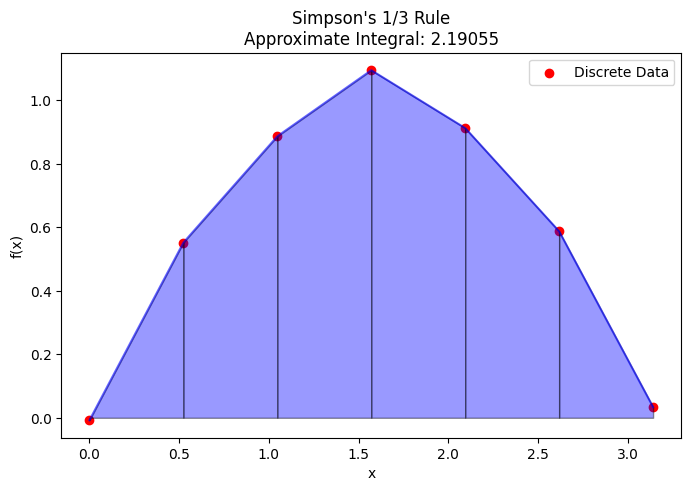

In [70]:
plot_simpson(a, b, '1/3', discrete_data)

In [71]:
# Example for Simpson's 3/8 rule
a, b = 0, np.pi
n = 10    # Should be a multiple of 3

In [72]:
discrete_x = np.linspace(a, b, n)
discrete_y = np.sin(discrete_x) + np.random.normal(0, 0.05, len(discrete_x))
discrete_data = list(discrete_y)

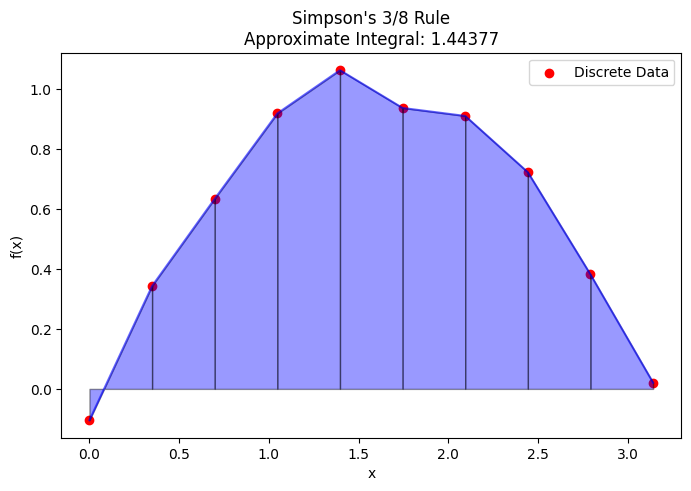

In [73]:
plot_simpson(a, b, '3/8', discrete_data)

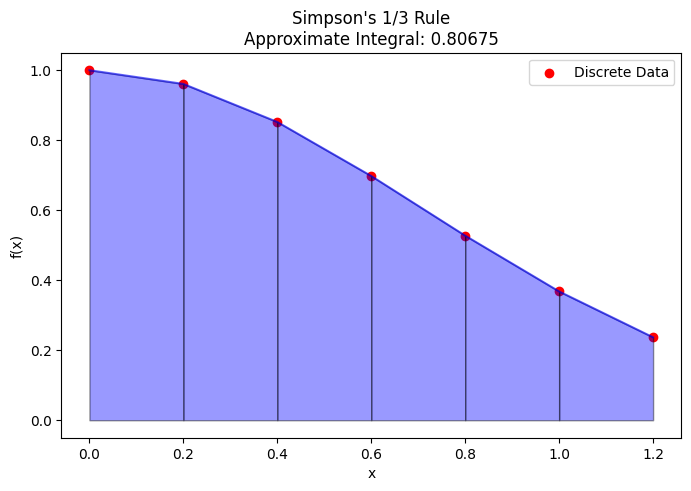

In [74]:
# Example with given data points
# given_x = np.array([1, 2, 3, 4, 5, 6, 7])
# given_y = np.array([1, 4, 7, 14, 20, 27, 35])
given_x = np.array([0, 0.2, 0.3, 0.6, 0.8, 1, 1.2])
given_y = np.array([1, 0.9608, 0.8521, 0.6977, 0.5273, 0.3679, 0.2369])
plot_simpson(given_x[0], given_x[-1], '1/3', given_y)

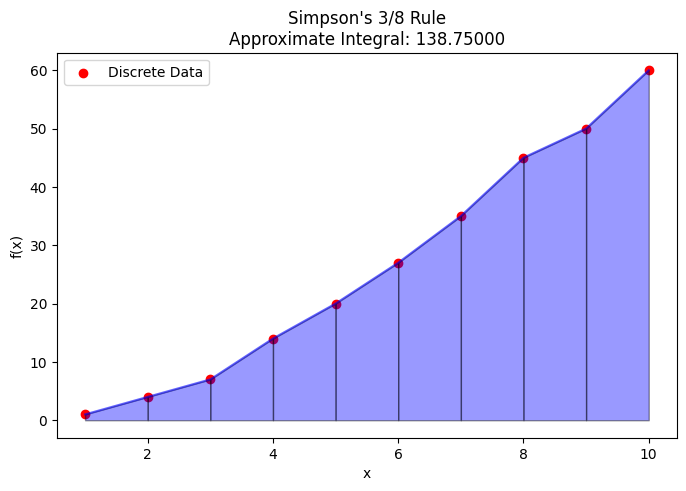

In [75]:
# Example with given data points for 3/8 rule
given_x_38 = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10])
given_y_38 = np.array([1, 4, 7, 14, 20, 27, 35, 45, 50, 60])
plot_simpson(given_x_38[0], given_x_38[-1], '3/8', given_y_38)